# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Mahardika Indra Pratama Ilyasa | 5054251045 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import kagglehub
from kagglehub import KaggleDatasetAdapter
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score, confusion_matrix)

torch.manual_seed(42)
np.random.seed(42)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

path = kagglehub.dataset_download("shrutimechlearn/churn-modelling")
print("Dataset berhasil diunduh dari: ", path)
files = os.listdir(path)
csv_filename = [f for f in files if f.endswith('.csv')][0]
csv_path = os.path.join(path, csv_filename)
df = pd.read_csv(csv_path)
print("First 5 records:", df.head())
print("Number of rows and columns:", df.shape)
print("Data types:", df.dtypes)
print("Descriptive statistics:", df.describe())
print("Missing values:", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Using Colab cache for faster access to the 'churn-modelling' dataset.
Dataset berhasil diunduh dari:  /kaggle/input/churn-modelling
First 5 records:    RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   Estima

Exited
0    7963
1    2037
Name: count, dtype: int64
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


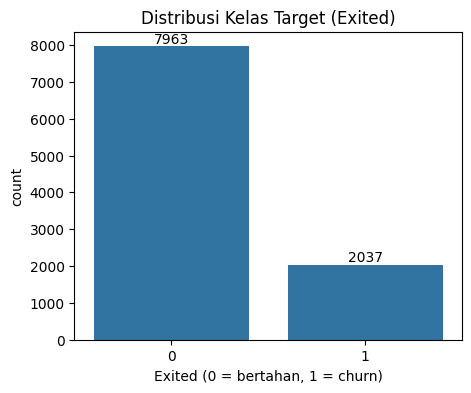

Rasio kelas 0 : kelas 1 = 3.91 : 1


In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.


print(df['Exited'].value_counts())
print(df['Exited'].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x='Exited', data=df)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Distribusi Kelas Target (Exited)')
plt.xlabel('Exited (0 = bertahan, 1 = churn)')
plt.show()

ratio = (df['Exited'] == 0).sum() / (df['Exited'] == 1).sum()
print(f"Rasio kelas 0 : kelas 1 = {ratio:.2f} : 1")


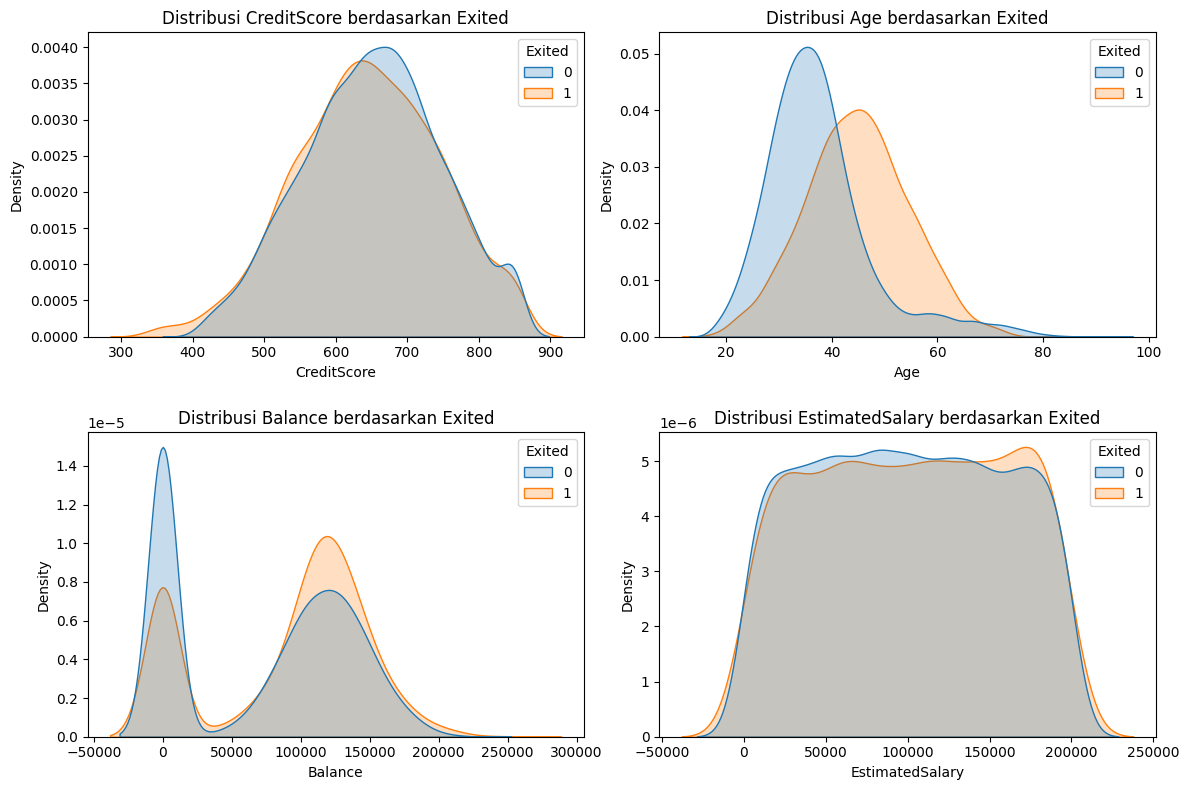

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.


num_cols_eda = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_cols_eda):
    sns.kdeplot(data=df, x=col, hue='Exited', common_norm=False, fill=True, ax=ax)
    ax.set_title(f'Distribusi {col} berdasarkan Exited')
plt.tight_layout()
plt.show()

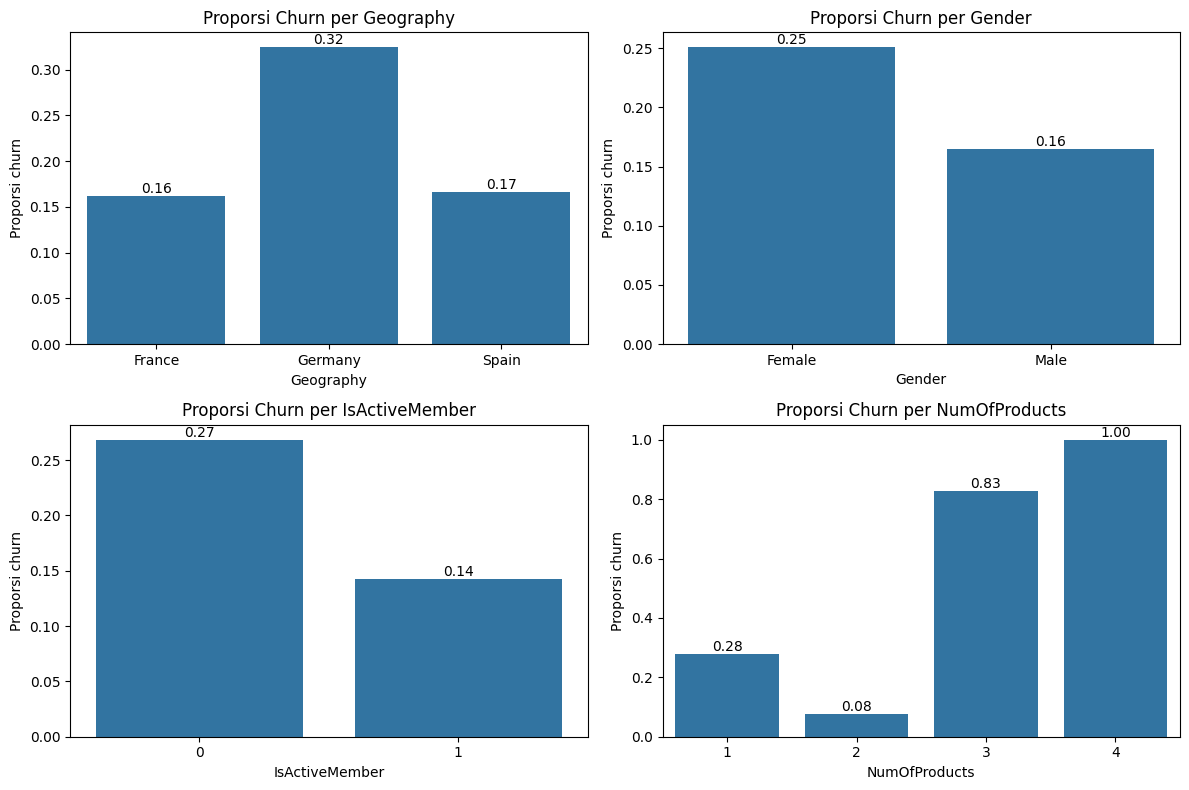

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).


cat_cols_eda = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    churn_rate = df.groupby(col)['Exited'].mean()
    sns.barplot(x=churn_rate.index.astype(str), y=churn_rate.values, ax=ax)
    ax.set_title(f'Proporsi Churn per {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Proporsi churn')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

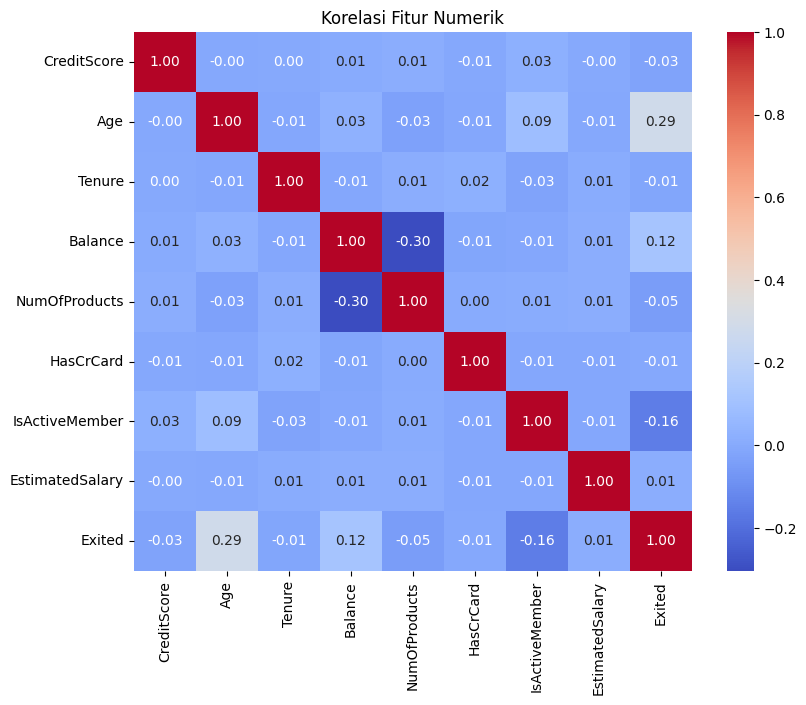

Proporsi Balance == 0: 0.362


In [6]:
# Korelasi antar fitur numerik dan target
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns=['RowNumber', 'CustomerId']).select_dtypes('number').corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Fitur Numerik')
plt.show()

print("Proporsi Balance == 0:", (df['Balance'] == 0).mean().round(3))

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [7]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

df_model = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
print(df_model.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.


X = df_model.drop(columns='Exited')
y = df_model['Exited']

# 70% train, 30% sisanya dibagi dua menjadi 15% validation dan 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

for name, yy in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f"{name:<11}: {len(yy):>5} data, proporsi churn = {yy.mean():.4f}")

Train      :  7000 data, proporsi churn = 0.2037
Validation :  1500 data, proporsi churn = 0.2040
Test       :  1500 data, proporsi churn = 0.2033


In [9]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.


numeric_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
binary_features = ['HasCrCard', 'IsActiveMember']   # sudah 0/1, cukup diteruskan

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('geo', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), ['Geography']),
    ('gender', OneHotEncoder(drop='if_binary', sparse_output=False), ['Gender']),  # Gender -> 0/1
    ('bin', 'passthrough', binary_features),
])

# fit hanya pada train set agar tidak terjadi data leakage
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

print("Fitur setelah preprocessing:", list(preprocessor.get_feature_names_out()))
print("Shape train/val/test:", X_train_p.shape, X_val_p.shape, X_test_p.shape)

Fitur setelah preprocessing: ['num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__EstimatedSalary', 'geo__Geography_France', 'geo__Geography_Germany', 'geo__Geography_Spain', 'gender__Gender_Male', 'bin__HasCrCard', 'bin__IsActiveMember']
Shape train/val/test: (7000, 12) (1500, 12) (1500, 12)


In [10]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.


def to_tensor_X(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)

def to_tensor_y(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32).view(-1, 1)

X_train_t, y_train_t = to_tensor_X(X_train_p), to_tensor_y(y_train)
X_val_t, y_val_t = to_tensor_X(X_val_p), to_tensor_y(y_val)
X_test_t, y_test_t = to_tensor_X(X_test_p), to_tensor_y(y_test)

BATCH_SIZE = 64
g = torch.Generator().manual_seed(42)
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                          batch_size=BATCH_SIZE, shuffle=True, generator=g)

input_dim = X_train_t.shape[1]
print("input_dim:", input_dim, "| y_train_t:", tuple(y_train_t.shape))

input_dim: 12 | y_train_t: (7000, 1)


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [11]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.


log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_p, y_train)

lr_pred = log_reg.predict(X_test_p)
lr_proba = log_reg.predict_proba(X_test_p)[:, 1]

results = {'Logistic Regression': {'pred': lr_pred, 'proba': lr_proba}}
print("Test accuracy:", round(accuracy_score(y_test, lr_pred), 4))

Test accuracy: 0.8153


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [12]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).


class SimpleANN(nn.Module):
    def __init__(self, input_dim, hidden=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),   # output logit (tanpa Sigmoid, karena memakai BCEWithLogitsLoss)
        )

    def forward(self, x):
        return self.net(x)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

torch.manual_seed(42)
model_simple = SimpleANN(input_dim)
print(model_simple)
print("Jumlah parameter:", count_params(model_simple))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [13]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.


LR = 1e-3
EPOCHS = 100

def train_model(model, criterion, optimizer, epochs=EPOCHS, verbose_every=20):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            logits = model(xb)
            loss = criterion(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # evaluasi di akhir epoch pada seluruh train dan validation set
        model.eval()
        with torch.no_grad():
            for name, Xs, ys in [('train', X_train_t, y_train_t), ('val', X_val_t, y_val_t)]:
                logits = model(Xs)
                history[f'{name}_loss'].append(criterion(logits, ys).item())
                preds = (torch.sigmoid(logits) >= 0.5).float()
                history[f'{name}_acc'].append((preds == ys).float().mean().item())

        if epoch % verbose_every == 0 or epoch == 1:
            print(f"Epoch {epoch:>3}/{epochs} | "
                  f"train loss {history['train_loss'][-1]:.4f} acc {history['train_acc'][-1]:.4f} | "
                  f"val loss {history['val_loss'][-1]:.4f} acc {history['val_acc'][-1]:.4f}")
    return history

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_simple.parameters(), lr=LR)
hist_simple = train_model(model_simple, criterion, optimizer)

Epoch   1/100 | train loss 0.4913 acc 0.7963 | val loss 0.4937 acc 0.7960
Epoch  20/100 | train loss 0.3505 acc 0.8521 | val loss 0.3348 acc 0.8547
Epoch  40/100 | train loss 0.3428 acc 0.8573 | val loss 0.3295 acc 0.8607
Epoch  60/100 | train loss 0.3387 acc 0.8583 | val loss 0.3264 acc 0.8633
Epoch  80/100 | train loss 0.3365 acc 0.8591 | val loss 0.3248 acc 0.8613
Epoch 100/100 | train loss 0.3345 acc 0.8613 | val loss 0.3222 acc 0.8613


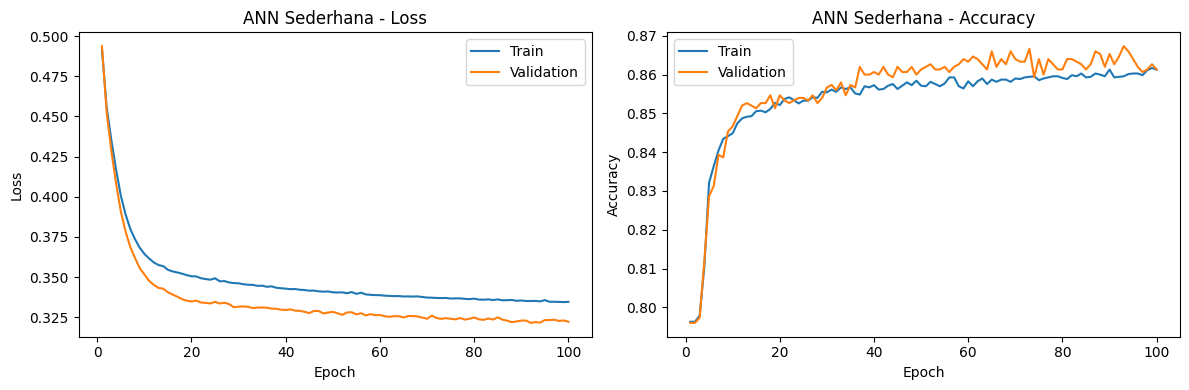

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.


def plot_history(history, title):
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_range, history['train_loss'], label='Train')
    axes[0].plot(epochs_range, history['val_loss'], label='Validation')
    axes[0].set_title(f'{title} - Loss')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()
    axes[1].plot(epochs_range, history['train_acc'], label='Train')
    axes[1].plot(epochs_range, history['val_acc'], label='Validation')
    axes[1].set_title(f'{title} - Accuracy')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(hist_simple, 'ANN Sederhana')

In [15]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.


def predict(model, X):
    model.eval()
    with torch.no_grad():
        proba = torch.sigmoid(model(X)).numpy().ravel()
    label = (proba >= 0.5).astype(int)
    return proba, label

proba_simple, pred_simple = predict(model_simple, X_test_t)
results['ANN Sederhana'] = {'pred': pred_simple, 'proba': proba_simple}
print("Test accuracy:", round(accuracy_score(y_test, pred_simple), 4))

Test accuracy: 0.8647


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [16]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.


class DeepANN(nn.Module):
    def __init__(self, input_dim, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model_deep = DeepANN(input_dim)
print(model_deep)
print("Jumlah parameter:", count_params(model_deep))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch   1/100 | train loss 0.4563 acc 0.7963 | val loss 0.4485 acc 0.7960
Epoch  20/100 | train loss 0.3341 acc 0.8644 | val loss 0.3250 acc 0.8680
Epoch  40/100 | train loss 0.3221 acc 0.8679 | val loss 0.3221 acc 0.8720
Epoch  60/100 | train loss 0.3128 acc 0.8730 | val loss 0.3244 acc 0.8687
Epoch  80/100 | train loss 0.3061 acc 0.8753 | val loss 0.3248 acc 0.8660
Epoch 100/100 | train loss 0.3015 acc 0.8793 | val loss 0.3267 acc 0.8660


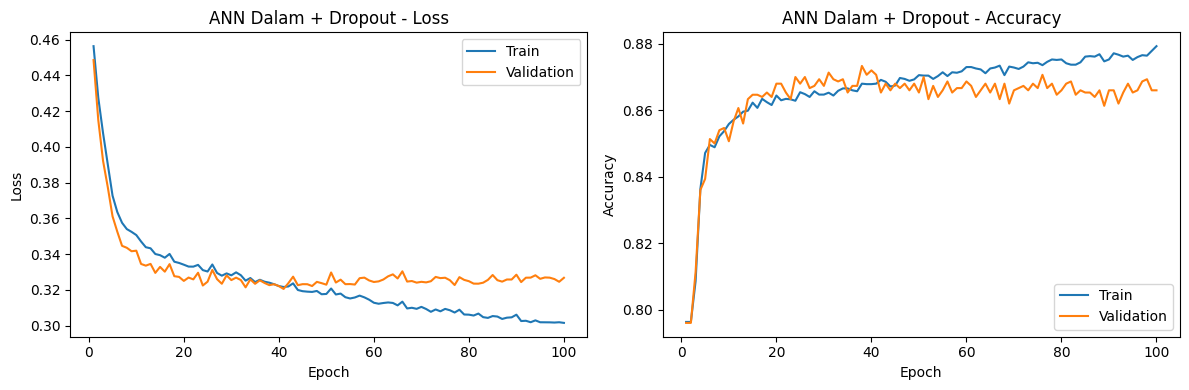

In [17]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?


criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_deep.parameters(), lr=LR)
hist_deep = train_model(model_deep, criterion, optimizer)
plot_history(hist_deep, 'ANN Dalam + Dropout')

# gap antara kurva train dan validation (loss train jauh lebih rendah dari validation,
# atau val loss mulai naik) menandakan overfitting.

In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.


proba_deep, pred_deep = predict(model_deep, X_test_t)
results['ANN Dalam + Dropout'] = {'pred': pred_deep, 'proba': proba_deep}
print("Test accuracy:", round(accuracy_score(y_test, pred_deep), 4))

Test accuracy: 0.8653


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [19]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).


# Pilih arsitektur terbaik berdasarkan validation loss minimum (bukan test set, agar tidak leakage).
best_simple = min(hist_simple['val_loss'])
best_deep = min(hist_deep['val_loss'])
if best_simple <= best_deep:
    best_arch, best_name = SimpleANN, 'ANN Sederhana'
else:
    best_arch, best_name = DeepANN, 'ANN Dalam + Dropout'
print(f"Min val loss: sederhana={best_simple:.4f}, dalam+dropout={best_deep:.4f} -> pakai {best_name}")

# pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
pos_weight = n_neg / n_pos
print(f"pos_weight = {n_neg}/{n_pos} = {pos_weight:.3f}")

torch.manual_seed(42)   # buat ulang model agar bobot mulai dari awal
model_weighted = best_arch(input_dim)
criterion_w = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer = torch.optim.Adam(model_weighted.parameters(), lr=LR)
hist_weighted = train_model(model_weighted, criterion_w, optimizer)

Min val loss: sederhana=0.3214, dalam+dropout=0.3205 -> pakai ANN Dalam + Dropout
pos_weight = 5574/1426 = 3.909
Epoch   1/100 | train loss 0.9610 acc 0.6741 | val loss 0.9462 acc 0.6747
Epoch  20/100 | train loss 0.7142 acc 0.8166 | val loss 0.6983 acc 0.8100
Epoch  40/100 | train loss 0.6874 acc 0.7983 | val loss 0.6945 acc 0.7853
Epoch  60/100 | train loss 0.6677 acc 0.8116 | val loss 0.6968 acc 0.7940
Epoch  80/100 | train loss 0.6470 acc 0.8101 | val loss 0.7026 acc 0.7880
Epoch 100/100 | train loss 0.6333 acc 0.8086 | val loss 0.7103 acc 0.7867


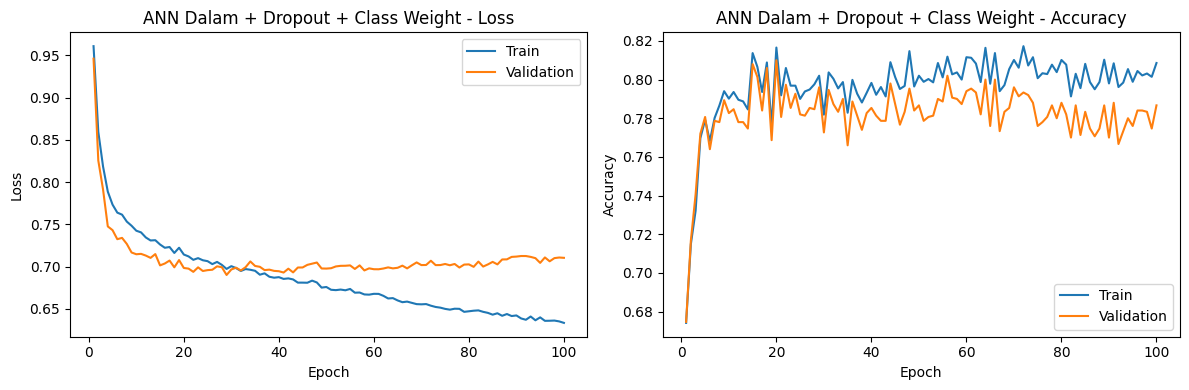

Test accuracy: 0.7873


In [20]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.


plot_history(hist_weighted, f'{best_name} + Class Weight')
# Catatan: loss pada model ini sudah dibobot (pos_weight), sehingga nilainya tidak bisa
# dibandingkan langsung dengan loss model lain. Bandingkan bentuk kurvanya saja.

proba_w, pred_w = predict(model_weighted, X_test_t)
results['ANN + Class Weight'] = {'pred': pred_w, 'proba': proba_w}
print("Test accuracy:", round(accuracy_score(y_test, pred_w), 4))

# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.


rows = []
for name, r in results.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, r['pred']),
        'Precision': precision_score(y_test, r['pred'], zero_division=0),
        'Recall': recall_score(y_test, r['pred']),
        'F1-Score': f1_score(y_test, r['pred']),
        'AUC': roc_auc_score(y_test, r['proba']),
    })
metrics_df = pd.DataFrame(rows).set_index('Model').round(4)
metrics_df

,Accuracy,Precision,Recall,F1-Score,AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
ANN Sederhana,0.8647,0.7833,0.4623,0.5814,0.8715
ANN Dalam + Dropout,0.8653,0.7725,0.4787,0.5911,0.8623
ANN + Class Weight,0.7873,0.4856,0.7738,0.5967,0.8655


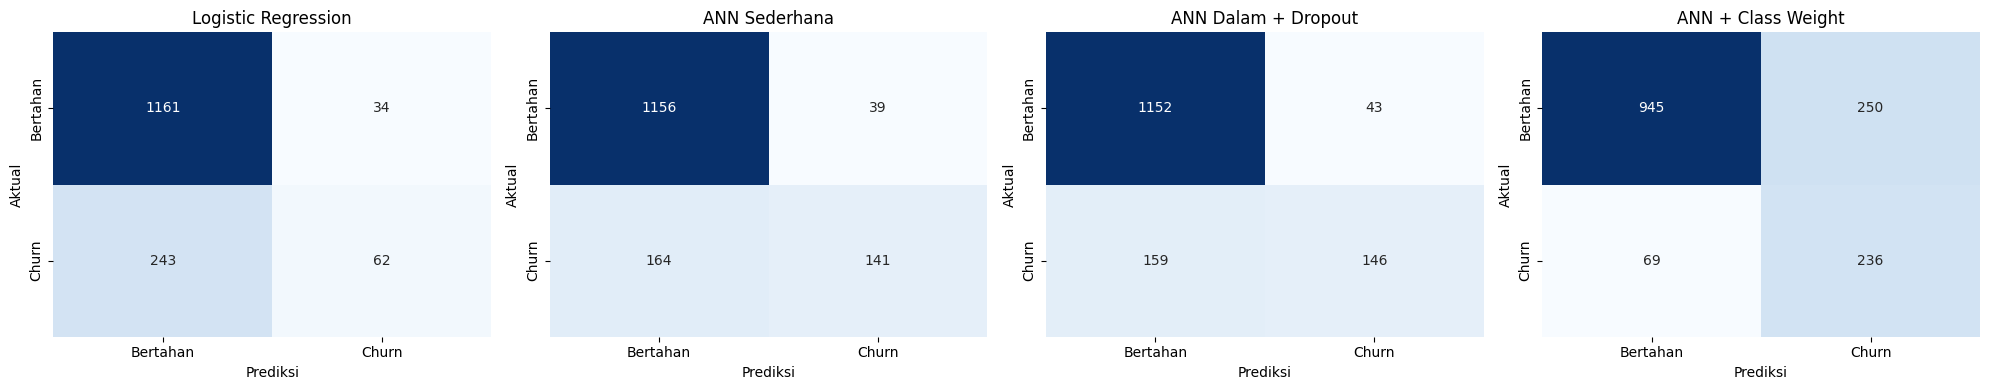

In [22]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.


fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r['pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Bertahan', 'Churn'], yticklabels=['Bertahan', 'Churn'])
    ax.set_title(name)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout()
plt.show()

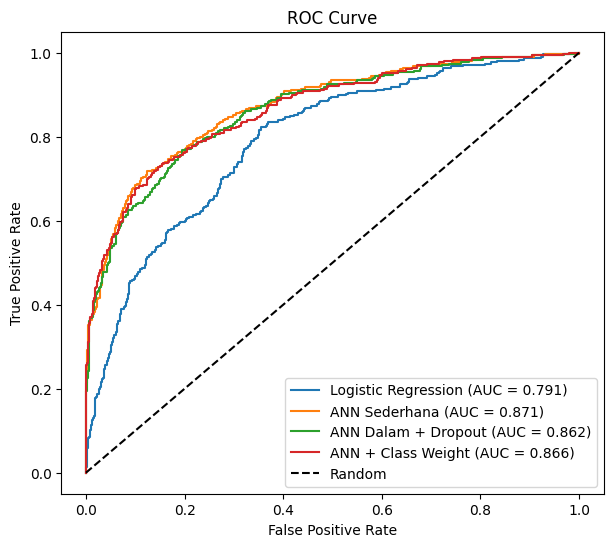

In [23]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.


plt.figure(figsize=(7, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r['proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, r['proba']):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [24]:
# Ringkasan learning curve untuk bahan analisis
histories = {
    'ANN Sederhana': hist_simple,
    'ANN Dalam + Dropout': hist_deep,
    'ANN + Class Weight': hist_weighted,
}
rows = []
for name, h in histories.items():
    best_ep = int(np.argmin(h['val_loss'])) + 1
    rows.append({
        'Model': name,
        'Best epoch (val loss)': best_ep,
        'Min val loss': min(h['val_loss']),
        'Final train loss': h['train_loss'][-1],
        'Final val loss': h['val_loss'][-1],
        'Final train acc': h['train_acc'][-1],
        'Final val acc': h['val_acc'][-1],
        'Gap loss (val-train)': h['val_loss'][-1] - h['train_loss'][-1],
    })
pd.DataFrame(rows).set_index('Model').round(4)

,Best epoch (val loss),Min val loss,Final train loss,Final val loss,Final train acc,Final val acc,Gap loss (val-train)
Model,,,,,,,
ANN Sederhana,92,0.3214,0.3345,0.3222,0.8613,0.8613,-0.0124
ANN Dalam + Dropout,41,0.3205,0.3015,0.3267,0.8793,0.8660,0.0252
ANN + Class Weight,29,0.6900,0.6333,0.7103,0.8086,0.7867,0.0770


# 5. Analisis

## 5.1 Perbandingan Performa Model

Dataset bersifat imbalanced: kelas churn hanya sekitar 20,4% (rasio 3,91 : 1 terhadap kelas bertahan). Artinya model yang selalu menebak "bertahan" sudah mencapai accuracy sekitar 79,7% tanpa mempelajari apa pun. Karena itu accuracy tidak boleh dibaca sendirian; Recall, F1, dan AUC kelas churn lebih menentukan.

| Model | Accuracy | Precision | Recall | F1-Score | AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0,8153 | 0,6458 | 0,2033 | 0,3092 | 0,7913 |
| ANN Sederhana | 0,8647 | 0,7833 | 0,4623 | 0,5814 | 0,8715 |
| ANN Dalam + Dropout | 0,8653 | 0,7725 | 0,4787 | 0,5911 | 0,8623 |
| ANN + Class Weight | 0,7873 | 0,4856 | 0,7738 | 0,5967 | 0,8655 |

**Logistic Regression (baseline).** Accuracy-nya 0,8153, hanya sedikit di atas tebakan kelas mayoritas, dan recall-nya hanya 0,2033: sekitar 80% nasabah yang benar-benar churn tidak terdeteksi. AUC 0,7913 juga yang terendah. Model linear tampaknya kurang mampu menangkap pola churn pada data ini, kemungkinan karena hubungan antara fitur (misalnya Age, NumOfProducts, Geography) dan churn tidak linear atau melibatkan interaksi antar fitur.

**ANN Sederhana (1 hidden layer, 225 parameter).** Dengan hanya satu hidden layer berisi 16 neuron, semua metrik naik jauh dibanding baseline: accuracy +0,049, F1 dari 0,3092 menjadi 0,5814, dan AUC dari 0,7913 menjadi 0,8715 (tertinggi di antara semua model). Ini menunjukkan bahwa kemampuan non-linear ANN memberi manfaat nyata. Meski begitu recall masih 0,4623, sehingga lebih dari separuh nasabah churn masih terlewat.

**ANN Dalam + Dropout (3 hidden layer, 3.457 parameter).** Hasilnya hampir sama dengan ANN sederhana: accuracy 0,8653 (+0,0006), F1 0,5911 (+0,0097), recall 0,4787 (+0,0164), sedangkan AUC justru turun 0,0092 menjadi 0,8623. Selisih sekecil ini tidak cukup untuk menyimpulkan model yang lebih dalam benar-benar lebih baik: test set hanya berisi 1.500 data dengan sekitar 305 nasabah churn, sehingga selisih recall 0,0164 setara dengan sekitar 5 nasabah, dan eksperimen hanya dijalankan dengan satu seed. Penambahan kedalaman pada data tabular dengan hanya 12 fitur ini memberi keuntungan yang sangat terbatas.

**ANN + Class Weight.** Arsitektur yang dipakai adalah ANN Dalam + Dropout (dipilih otomatis karena val loss minimumnya paling kecil, 0,3205 vs 0,3214), dengan `pos_weight` = 3,909. Recall melonjak dari 0,4787 menjadi 0,7738 (+0,295), tetapi precision turun dari 0,7725 menjadi 0,4856 dan accuracy turun menjadi 0,7873, bahkan lebih rendah dari Logistic Regression. F1 0,5967 tertinggi, tetapi hanya unggul tipis dari model tanpa bobot. AUC-nya (0,8655) hampir sama dengan model tanpa bobot (0,8623), artinya kemampuan model membedakan churn dan non-churn secara umum tidak berubah; yang berubah adalah titik operasi (trade-off precision-recall) pada threshold 0,5.

## 5.2 Analisis Learning Curve

| Model | Best epoch (val loss) | Min val loss | Final train loss | Final val loss | Gap (val - train) |
|---|---|---|---|---|---|
| ANN Sederhana | 92 | 0,3214 | 0,3345 | 0,3222 | -0,0124 |
| ANN Dalam + Dropout | 41 | 0,3205 | 0,3015 | 0,3267 | +0,0252 |
| ANN + Class Weight | 29 | 0,6900 | 0,6333 | 0,7103 | +0,0770 |

- **ANN Sederhana: tidak overfitting, cenderung underfitting ringan.** Train dan validation loss turun bersamaan dan nyaris menyatu (train 0,3345 vs val 0,3222), tanpa tanda val loss naik. Best epoch berada di epoch 92 dan loss masih turun pelan sampai epoch 100, jadi model belum sepenuhnya konvergen dan kapasitasnya kecil (hanya 225 parameter). Val loss yang sedikit lebih rendah dari train loss kemungkinan hanya akibat perbedaan sampel pada split data, bukan keunggulan sistematis.
- **ANN Dalam + Dropout: overfitting ringan setelah sekitar epoch 40.** Val loss mencapai minimum 0,3205 di epoch 41, lalu naik menjadi 0,3267 sementara train loss terus turun menjadi 0,3015. Gap-nya +0,0252 dan val accuracy turun dari 0,8720 (epoch 40) menjadi 0,8660 sementara train accuracy naik ke 0,8793. Overfitting yang terjadi kecil, yang menunjukkan Dropout 0,3 cukup membantu menahannya, tetapi tidak menghilangkannya sepenuhnya. Pelatihan 100 epoch sebenarnya berlebih untuk model ini.
- **ANN + Class Weight: overfitting paling jelas.** Val loss minimum sudah tercapai di epoch 29 (0,6900), kemudian naik menjadi 0,7103 sedangkan train loss turun ke 0,6333, dengan gap +0,0770 yang terbesar di antara ketiga model. Val accuracy juga turun dari sekitar 0,81 menjadi 0,7867 dan berfluktuasi. Nilai loss pada model ini tidak bisa dibandingkan langsung dengan model lain karena sudah dibobot oleh `pos_weight`; yang dibandingkan hanya bentuk kurvanya. Memberi bobot besar pada kelas minoritas membuat model terus menyesuaikan diri pada sampel churn di train set (hanya 1.426 data), sehingga lebih mudah menghafal.

## 5.3 Pengaruh Penambahan Layer dan Dropout

Menambah layer dari 1 menjadi 3 hidden layer (225 menjadi 3.457 parameter) menurunkan train loss lebih rendah (0,3015 vs 0,3345) tetapi nyaris tidak memperbaiki generalisasi: min val loss hanya membaik 0,0009 dan metrik test hampir identik, dengan AUC bahkan sedikit turun. Kapasitas tambahan lebih banyak terpakai untuk menyesuaikan train set (muncul gap) daripada menangkap pola baru. Dropout berperan menjaga gap tetap kecil (+0,0252), namun tanpa pembanding model dalam tanpa Dropout, besarnya kontribusi Dropout di sini tidak bisa dipastikan dari eksperimen ini.

## 5.4 Pengaruh Class Weight terhadap Precision dan Recall Kelas Churn

Class weight menggeser keseimbangan precision-recall secara tajam: recall naik 0,4787 menjadi 0,7738, precision turun 0,7725 menjadi 0,4856. Dengan bobot 3,909, kesalahan pada nasabah churn dihukum hampir 4 kali lebih berat, sehingga model berani memprediksi churn lebih sering. Akibatnya lebih banyak nasabah churn yang berhasil terdeteksi, tetapi lebih banyak pula nasabah setia yang salah ditandai (false positive) dan accuracy turun. Kenaikan F1 yang kecil (0,5911 menjadi 0,5967) dan AUC yang hampir sama menegaskan bahwa class weight bukan membuat model "lebih pintar", melainkan memindahkan titik keputusannya. Pilihan antara model dengan atau tanpa bobot bergantung pada biaya bisnis: bila kehilangan nasabah jauh lebih mahal daripada biaya menawarkan promosi retensi ke nasabah yang sebenarnya tidak akan pergi, recall tinggi lebih diutamakan.

# 6. Kesimpulan dan Saran

## Kesimpulan

1. Semua model ANN mengungguli baseline Logistic Regression. AUC naik dari 0,7913 menjadi 0,86-0,87 dan F1 dari 0,3092 menjadi 0,58-0,60, sehingga pemodelan non-linear terbukti bermanfaat pada data churn ini.
2. Menambah kedalaman dan Dropout hanya memberi perbaikan yang sangat kecil (F1 0,5814 menjadi 0,5911, AUC justru turun dari 0,8715 menjadi 0,8623). ANN sederhana dengan 225 parameter sudah hampir sebaik model dengan 3.457 parameter, dan pada learning curve-nya tidak terlihat overfitting.
3. Model yang lebih kompleks mulai overfitting: ANN Dalam + Dropout setelah sekitar epoch 40 (gap +0,0252) dan ANN + Class Weight setelah sekitar epoch 29 (gap +0,0770). Melatih sampai 100 epoch tanpa early stopping tidak diperlukan.
4. Class weight mengubah perilaku model, bukan kualitas ranking-nya. Recall churn naik dari 0,4787 menjadi 0,7738 dengan harga precision turun dari 0,7725 menjadi 0,4856 dan accuracy turun ke 0,7873. AUC hampir tidak berubah.
5. Pemilihan model akhir bergantung tujuan. Untuk mendeteksi sebanyak mungkin nasabah yang akan churn, ANN + Class Weight paling sesuai (recall 0,7738, F1 tertinggi 0,5967). Untuk prediksi yang lebih akurat dan minim false positive, ANN Dalam + Dropout (accuracy 0,8653, precision 0,7725) atau ANN Sederhana (AUC tertinggi 0,8715) lebih tepat.

## Saran

- **Early stopping** berdasarkan val loss (atau menyimpan bobot di epoch terbaik), karena minimum val loss tercapai jauh sebelum epoch 100 pada model Dropout (epoch 41) dan Class Weight (epoch 29).
- **Tuning threshold** pada validation set (misalnya memilih threshold yang memaksimalkan F1 atau memenuhi target recall) sebagai alternatif class weight, yang menggeser trade-off tanpa mengubah training.
- **Pembanding yang lebih adil:** latih Logistic Regression dengan `class_weight='balanced'` dan ANN dalam tanpa Dropout, agar pengaruh class weight dan Dropout bisa dipisahkan dengan jelas.
- **Ulangi dengan beberapa random seed** atau gunakan cross-validation dan laporkan rata-rata serta simpangan baku, karena selisih antar model (misalnya ANN sederhana vs ANN dalam) kecil dan bisa berada dalam rentang noise.
- **Tuning hyperparameter** (jumlah neuron/layer, learning rate, nilai Dropout, weight decay) dan **feature engineering**, mengingat pada data tabular dengan 12 fitur arsitektur yang lebih dalam tidak otomatis memberi hasil lebih baik.
- **Coba teknik imbalanced lain** seperti oversampling (SMOTE) atau focal loss, serta model berbasis pohon (Random Forest, XGBoost) sebagai pembanding yang umumnya kuat untuk data tabular.